In [2]:

%cd ..

from pathlib import Path
print(Path.cwd())

import numpy as np
import matplotlib.pyplot as plt

from hardware import ammeter, ammeter_uncertainty, gaussmeter, gaussmeter_uncertainty, horizontal_coils, vertical_coils, modulation_coils, horizontal_coils_uncertainty, vertical_coils_uncertainty, modulation_coils_uncertainty
from scope_header import DSOX1204G, self_test, load_waveforms


plt.rcParams.update({
    "font.sans-serif": ["Cabin", "Libertinus Sans", "DejaVu Sans"],
    "font.serif": ["Libertinus Serif"],
    "font.family": "sans-serif",
    "font.style": "normal",
    "font.weight": "normal",
    "font.size": 14,
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.labelweight": "normal",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 14,
    "legend.title_fontsize": 14,
    "figure.titlesize": 18,
    "figure.titleweight": "bold",
    "mathtext.fontset": "cm",
    "mathtext.default": "it",
    "axes.unicode_minus": False,
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.titlecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "legend.edgecolor": "black",
})
%matplotlib inline

from scipy.optimize import curve_fit
from scipy import signal

# scope = DSOX1204G()


c:\Users\njwan\OneDrive - University of Toronto\Documents\Year 3\3F\PHY327\1 - Optical Pumping in Rubidium\code
c:\Users\njwan\OneDrive - University of Toronto\Documents\Year 3\3F\PHY327\1 - Optical Pumping in Rubidium\code


## Live

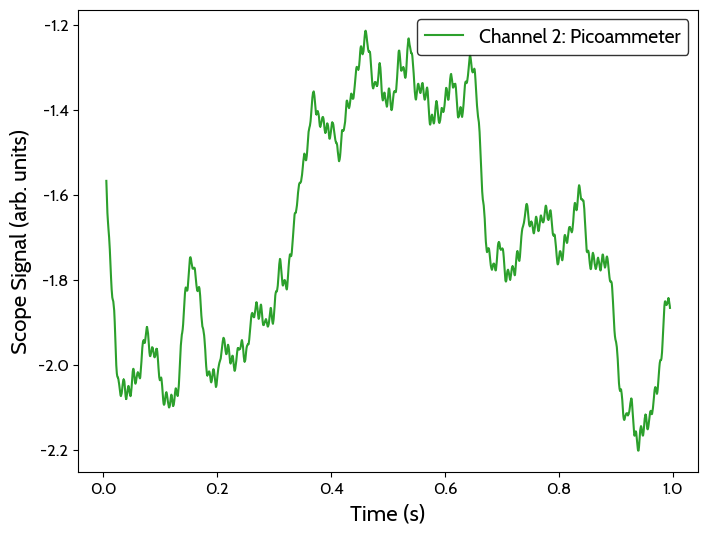

In [122]:
data = load_waveforms("data/32/50us_1190.npz")
t, V1, V2 = data[1][0], data[1][1], data[2][1]


N = 500
t = np.convolve(t, np.ones(N)/N, mode='valid')
V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
V2 = np.convolve(V2, np.ones(N)/N, mode='valid')

fig0, ax0 = plt.subplots(figsize=(8, 6))
# ax0.plot(t, V1, label='Channel 1: Gaussmeter', color='goldenrod')
ax0.plot(t, V2*5-2, label='Channel 2: Picoammeter', color='tab:green')
ax0.set_xlabel('Time (s)')
ax0.set_ylabel('Scope Signal (arb. units)')
ax0.legend()


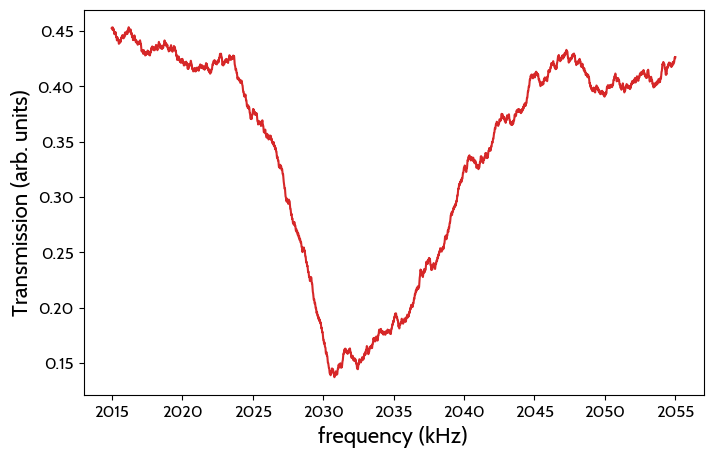

In [ ]:
def plot_average(dnums, filename, freq_low = 550, freq_high = 650):
    transmissions = []
    for dnum in dnums:
        data = load_waveforms(f"data/32/{filename}_{dnum}.npz")
        t, V1, V2 = data[1][0], data[1][1], data[2][1]
        N = 500
        t = np.convolve(t, np.ones(N)/N, mode='valid')
        V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
        transmissions.append(V2)
    np.array(transmissions)
    frequencies = np.linspace(freq_low, freq_high, len(t))
    avg_transmission = np.mean(transmissions, axis=0)
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(frequencies, avg_transmission, label='Average Transmission', color='tab:red')
    ax.set_xlabel('frequency (kHz)')
    ax.set_ylabel('Transmission (arb. units)')


# splitting attempt is freqs 2035 +/- 20 kHz @ 1mV
plot_average(range(1196, 1221), "splittings/1Vpp", freq_low=2015, freq_high=2055)

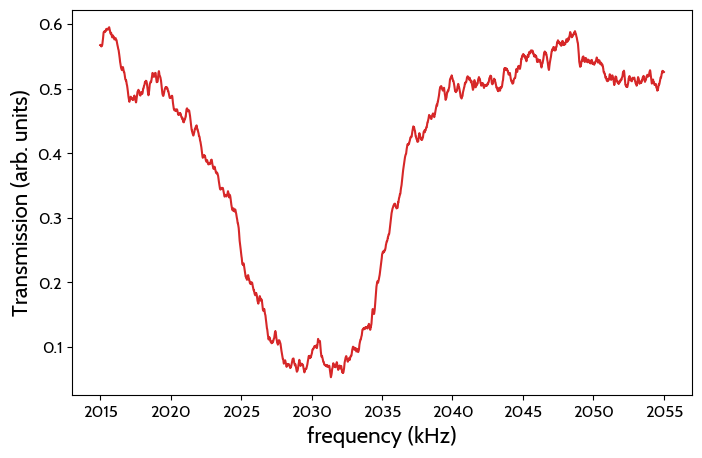

In [135]:
%matplotlib inline
# splitting attempt is freqs 2035 +/- 20 kHz @ 1mV
plot_average(range(1221, 1226), "splittings/2Vpp", freq_low=2015, freq_high=2055)

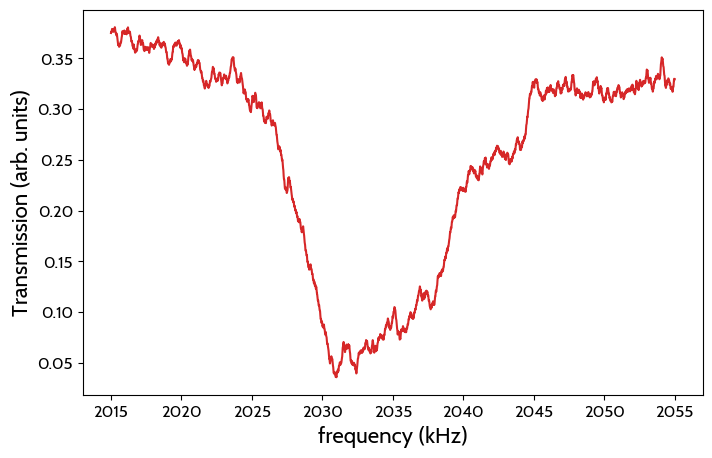

In [127]:
%matplotlib inline
# splitting attempt is freqs 2035 +/- 20 kHz @ 1mV
plot_average(range(1196, 1207), "splittings/1Vpp", freq_low=2015, freq_high=2055)

## Bulk Analysis

In [21]:
import glob

pulse_powers = glob.glob("data/32/pulse_powers/*.npz")
pulse_times = glob.glob("data/32/pulse_times/*.npz")
splittings = glob.glob("data/32/splittings/*.npz")


pulse_powers_data = {}
for file in pulse_powers:
    power = float(file.split("pulse_powers\\")[-1].split("Vpp_")[0])
    if power not in pulse_powers_data:
        pulse_powers_data[power] = []
    pulse_powers_data[power].append(file)

pulse_times_data = {}
for file in pulse_times:
    time = float(file.split("pulse_times\\")[-1].split("_")[0])
    if time not in pulse_times_data:
        pulse_times_data[time] = []
    pulse_times_data[time].append(file)


splittings_data = {}
for file in splittings:
    splitting = float(file.split("splittings\\")[-1].split("Vpp")[0])
    if splitting not in splittings_data:
        splittings_data[splitting] = []
    splittings_data[splitting].append(file)

In [105]:
def plot_average_pulse(filenames, pulselength = 0):
    transmissions = []
    for filename in filenames:
        data = load_waveforms(filename)
        t, V2, V4 = data[1][0], data[2][1], data[4][1]
        N = 100
        t = np.convolve(t, np.ones(N)/N, mode='valid')
        V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
        V4 = np.convolve(V4, np.ones(N)/N, mode='valid')
        transmissions.append(V2)
    np.array(transmissions)
    avg_transmission = np.mean(transmissions, axis=0)

    if pulselength != 0.125:
        pulselength = t[np.where(V4 > 2)[0][0]]

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(t, avg_transmission, label='Average Transmission', color='tab:red')

    ax.axvline(x=pulselength, color='tab:blue', linestyle='--', alpha=0.8)
    ax.axvspan(xmin=0, xmax=pulselength, color='tab:blue', alpha=0.1, hatch='//', label = "Pulse ON")
    ax.axvspan(xmin=pulselength, xmax=t[-1], color='tab:green', alpha=0.1, hatch='\\', label = "Pulse OFF")
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Transmission (arb. units)')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_xlim(t[0], t[-1])
    ax.legend()
    return fig


### pulse powers

In [66]:
# pulse powers
maxs = []
maxs_errors = []
powers = []
for power in pulse_powers_data:
    transmissions = []
    specific_maxs = []
    for filename in pulse_powers_data[power]:
        data = load_waveforms(filename)
        t, V2, V4 = data[1][0], data[2][1], data[4][1]
        N = 100
        t = np.convolve(t, np.ones(N)/N, mode='valid')
        V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
        V4 = np.convolve(V4, np.ones(N)/N, mode='valid')
        transmissions.append(V2)
        specific_maxs.append(np.max(V2) - np.min(V2))
    np.array(transmissions)
    np.array(specific_maxs)
    avg_transmission = np.mean(transmissions, axis=0)
    maxs_errors.append(np.std(specific_maxs) / np.sqrt(len(specific_maxs)))
    maxs.append(np.mean(specific_maxs))
    powers.append(power)


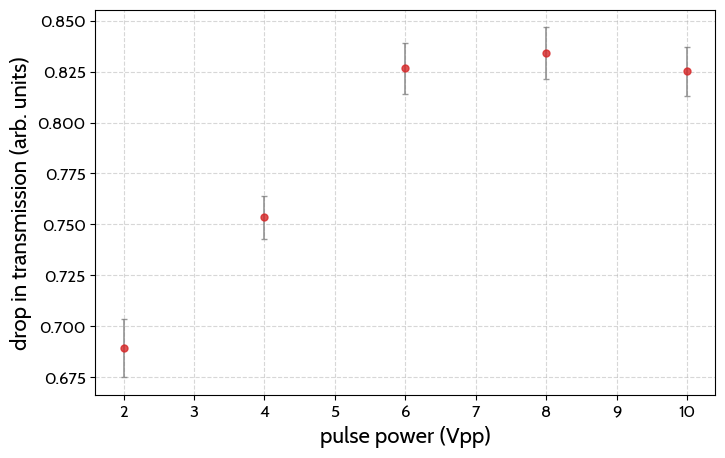

In [136]:

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(powers, maxs, yerr=maxs_errors, color = "tab:red", fmt='o', ms=5, ecolor='gray', alpha=0.8, elinewidth=1.25, capsize=2)
ax.set_xlabel('pulse power (Vpp)')
ax.set_ylabel('drop in transmission (arb. units)')
ax.grid(True, linestyle='--', alpha=0.5)



### pulse times

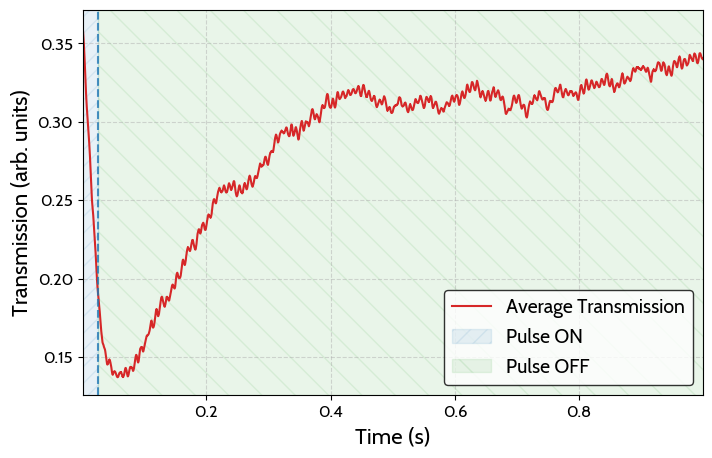

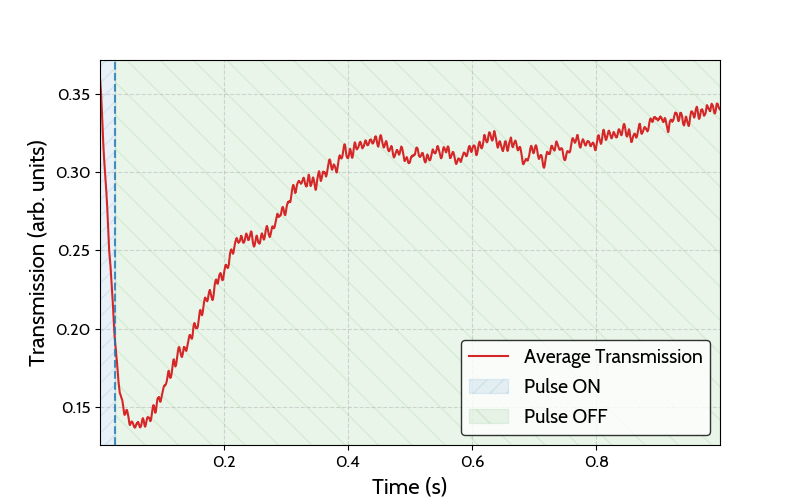

In [115]:
plot_average_pulse(pulse_times_data[1000])

In [82]:
maxs_time = []
maxs_time_errors = []
times = []

for cycles in [*pulse_times_data]:
    transmissions = []
    specific_maxs = []
    for filename in pulse_times_data[cycles]:
        data = load_waveforms(filename)
        t, V2, V4 = data[1][0], data[2][1], data[4][1]
        N = 100
        t = np.convolve(t, np.ones(N)/N, mode='valid')
        V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
        V4 = np.convolve(V4, np.ones(N)/N, mode='valid')
        transmissions.append(V2)
        specific_maxs.append(np.max(V2) - np.min(V2))
    np.array(transmissions)
    np.array(specific_maxs)
    avg_transmission = np.mean(transmissions, axis=0)
    maxs_time_errors.append(np.std(specific_maxs) / np.sqrt(len(specific_maxs)))
    maxs_time.append(np.mean(specific_maxs))
    times.append(cycles*10/400e3)
    

<ErrorbarContainer object of 3 artists>

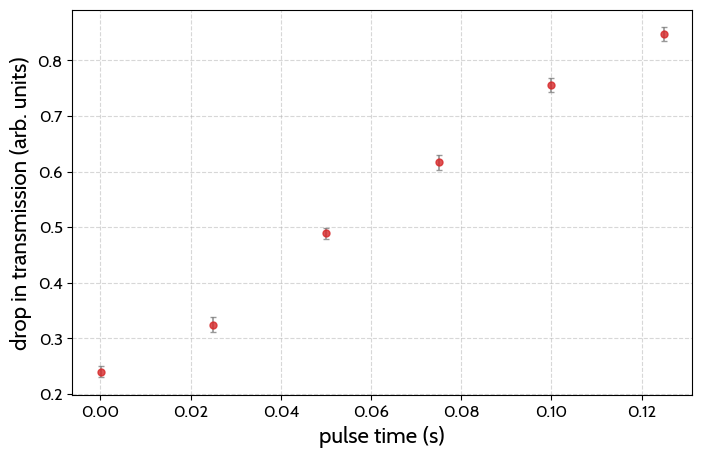

In [123]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(times, maxs_time, yerr=maxs_time_errors, color = "tab:red", fmt='o', ms=5, ecolor='gray', alpha=0.8, elinewidth=1.25, capsize=2)
ax.set_xlabel('pulse time (s)')
ax.set_ylabel('drop in transmission (arb. units)')
ax.grid(True, linestyle='--', alpha=0.5)
ax.errorbar(50e-6, 0.24, yerr = 0.01, color = "tab:red", fmt='o', ms=5, ecolor='gray', alpha=0.8, elinewidth=1.25, capsize=2, label="50us pulse")

## Micro Pulse

0.24553809029880008
0.010495804829640975


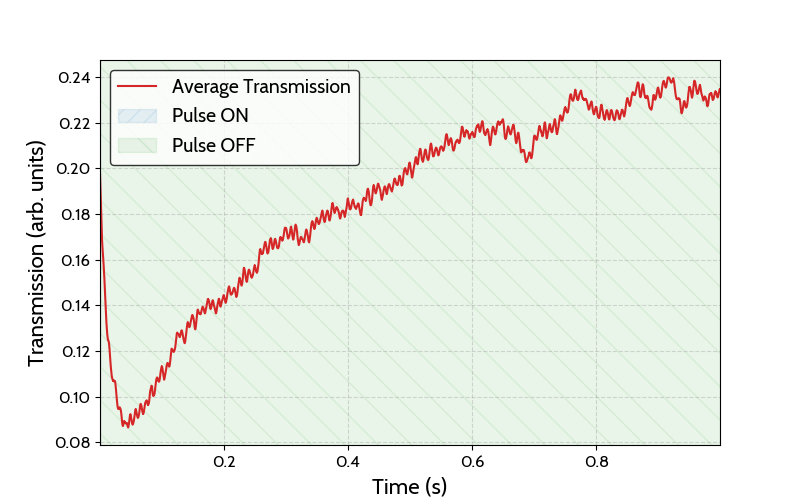

In [117]:
micro_pulse_data = glob.glob("data/32/50us*.npz")
plot_average_pulse(micro_pulse_data[0:30], pulselength=50e-6)

specific_maxs = []
for filename in micro_pulse_data:
    data = load_waveforms(filename)
    t, V2, V4 = data[1][0], data[2][1], data[4][1]
    N = 500
    V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
    specific_maxs.append(np.max(V2) - np.min(V2))
np.array(transmissions)
np.array(specific_maxs)
print(np.mean(specific_maxs))
print(np.std(specific_maxs) / np.sqrt(len(specific_maxs)))


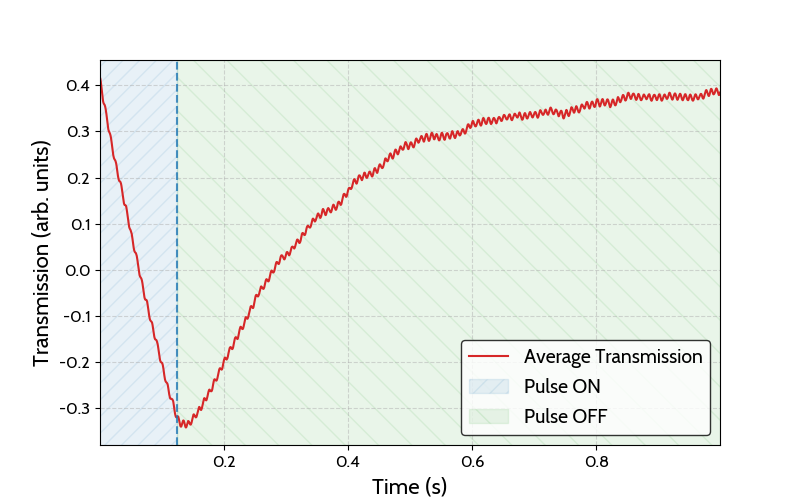

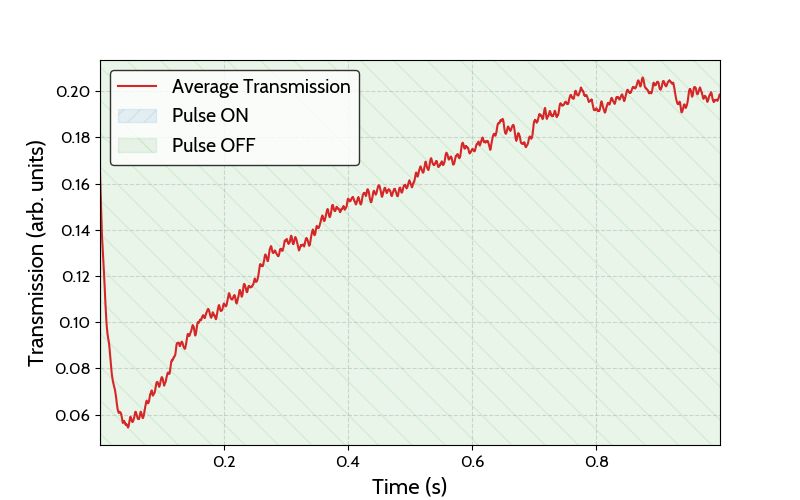

In [107]:
fig = plot_average_pulse(pulse_powers_data[10.0], pulselength=0.125)
fig.savefig("figures/long_pulse.svg", format='svg', bbox_inches='tight')
fig = plot_average_pulse(micro_pulse_data)
fig.savefig("figures/micro_pulse.svg", format='svg', bbox_inches='tight')